In [45]:
import BayesWorkFlow as bayes
import requests
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import scipy

In [ ]:
year = 2024
month = 12
day = 10
update_seasons = 'true'
start_year=year
end_year=year+1

requests.get(f'http://127.0.0.1:5000/update_games/year={year}/month={month}/day={day}/update_seasons={update_seasons}/start_year={start_year}/end_year={end_year}')

In [103]:
first_name = 'Jalen'
last_name = 'Brunson'
middle_name = None
stat = 'Points'
line_stat = 26.5
max_stat = 100
days = 3
opponent = 'Atlanta Hawks'

player_features = bayes.retrieve_player_features(stat, days, first_name, last_name, middle_name)
team_features = bayes.retrieve_team_features(stat, days, opponent)

test = bayes.run_bayes(stat, 2024, player_features, team_features, max_stat, first_name, last_name, days=5)
stat = np.arange(0, len(test), 1)
fitted_dist = scipy.stats.gaussian_kde(stat, weights=test)

x = np.linspace(0, max_stat, 1000)
distribution = fitted_dist(x)

result, _ = quad(fitted_dist, 0, line_stat)

print(result)

0.04237657509998346


In [104]:
interval = 0.05
end_points = interval
for i in range(len(distribution)):

    current, _ = quad(fitted_dist, 0, end_points)

    if current >= 0.50:
        break
    else:
        end_points += interval

In [105]:
print(end_points)
print(current)
print(player_features)
print(team_features)

38.99999999999992
0.5016935750323416
25.0
121.33333333333333


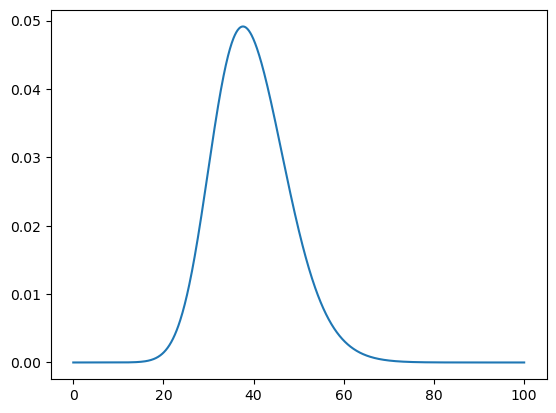

In [106]:
plt.plot(x, distribution)
plt.show()